# Geometry of GO Label Probes in ESM-2 Protein Embeddings

Computational appendix to the report *Geometric Structure of GO Label Probes in
Protein-Language-Model Embeddings*. Every number and figure in the report is
produced by this notebook.

The notebook starts from the cached artifacts in `protein_dataset/` (built by
`Protein.ipynb`), refits a one-vs-rest logistic probe on frozen ESM-2 embeddings,
and then asks four questions about the resulting weight matrix
$W \in \mathbb{R}^{75 \times 480}$:

| Section | Question |
| --- | --- |
| 3 | Q1-Q3: are any weight vectors exactly linearly dependent, and how far from it? |
| 4 | Q4: is the singular-value spectrum concentrated? |
| 5 | Which null models explain that concentration? |
| 6 | Does the geometry track label co-occurrence? |

Runtime is about 11 minutes, almost all of it in the permutation nulls of
Section 5.

## 1. Data

`Protein.ipynb` downloads reviewed Swiss-Prot records from the UniProt REST API,
keeps proteins with at least one GO Cellular Component annotation, and selects the
75 GO CC terms carried by at least 100 proteins. It then embeds every sequence with
ESM-2 (`esm2_t12_35M_UR50D`, layer 12, mean-pooled) and stores the arrays below.
`protein_dataset/README.md` documents the file formats.

| Artifact | Shape | Content |
| --- | --- | --- |
| `esm2_embeddings.npy` | 9,895 x 480 | mean-pooled sequence embeddings, one row per protein |
| `go_labels.npy` | 9,895 x 75 | binary multi-label target matrix |
| `protein_ids.csv` | 9,895 x 1 | row order of both arrays |
| `uniprot_swissprot_go_cc.csv` | 9,895 x 3 | source table (id, sequence, raw GO text) |
| `selected_go_labels.csv` | 75 x 1 | label names, in target-matrix column order |
| `go_cc_label_counts.csv` | 1,779 x 2 | protein count for every GO CC term in the export |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 250,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

DATA_DIR = Path("protein_dataset")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 2.3.3


In [2]:
raw = pd.read_csv(DATA_DIR / "uniprot_swissprot_go_cc.csv")
X = np.load(DATA_DIR / "esm2_embeddings.npy")
Y = np.load(DATA_DIR / "go_labels.npy")
protein_ids = pd.read_csv(DATA_DIR / "protein_ids.csv")["uniprot_id"].tolist()
labels = pd.read_csv(DATA_DIR / "selected_go_labels.csv")["go_id"].tolist()
label_counts = pd.read_csv(DATA_DIR / "go_cc_label_counts.csv")

assert X.shape[0] == Y.shape[0] == len(protein_ids) == len(raw)
assert Y.shape[1] == len(labels)

overview = pd.DataFrame({
    "quantity": [
        "protein records",
        "embedding dimensions",
        "selected GO CC labels",
        "positive label assignments",
        "mean labels per protein",
        "proteins with at least one selected label",
        "distinct GO CC terms in the export",
    ],
    "value": [
        f"{len(raw):,}",
        f"{X.shape[1]}",
        f"{len(labels)}",
        f"{int(Y.sum()):,}",
        f"{Y.sum(axis=1).mean():.4f}",
        f"{int((Y.sum(axis=1) > 0).sum()):,}",
        f"{len(label_counts):,}",
    ],
})
display(overview)

,quantity,value
0,protein records,"9,895"
1,embedding dimensions,480
2,selected GO CC labels,75
3,positive label assignments,"36,188"
4,mean labels per protein,3.6572
5,proteins with at least one selected label,"9,786"
6,distinct GO CC terms in the export,"1,779"


The label distribution is strongly skewed: `GO:0005634` (nucleus) is present in
3,360 proteins, while most of the 1,779 terms occur in only a handful. The
100-protein threshold keeps 75 labels, which is the width of `W`.

## 2. Linear probe

A one-vs-rest logistic regression is fitted on standardised embeddings, one binary
classifier per GO term:

$$p(y_{ni}=1 \mid x_n) = \sigma(w_i^\top x_n + b_i), \qquad
W = [w_1 \;\; \dots \;\; w_{75}]^\top \in \mathbb{R}^{75 \times 480}.$$

`W` is the object analysed in Sections 3-6.

### 2.1 Train/test split

In [3]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train", X_train.shape, "| X_test", X_test.shape)
print("Y_train", Y_train.shape, "| Y_test", Y_test.shape)

X_train (7916, 480) | X_test (1979, 480)
Y_train (7916, 75) | Y_test (1979, 75)


### 2.2 Fit and evaluate

In [4]:
def make_probe():
    '''One-vs-rest logistic regression on standardised embeddings.'''
    return make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(
            LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced"),
            n_jobs=-1,
        ),
    )


def probe_weights(fitted):
    '''Stack the 75 coefficient vectors into a (75, 480) matrix.'''
    ovr = fitted.named_steps["onevsrestclassifier"]
    return np.vstack([clf.coef_.ravel() for clf in ovr.estimators_])


probe = make_probe()
probe.fit(X_train, Y_train)
W = probe_weights(probe)
np.save(DATA_DIR / "probe_weights.npy", W)

print("W shape:", W.shape)

W shape: (75, 480)


In [5]:
Y_score = probe.predict_proba(X_test)

per_label = []
for k, go_id in enumerate(labels):
    column = Y_test[:, k]
    if column.min() == column.max():          # AUC undefined for a single-class fold
        continue
    per_label.append({
        "go_id": go_id,
        "roc_auc": roc_auc_score(column, Y_score[:, k]),
        "average_precision": average_precision_score(column, Y_score[:, k]),
    })

per_label = pd.DataFrame(per_label)
print(f"labels scored: {len(per_label)} / {len(labels)}")
print(f"mean ROC-AUC: {per_label.roc_auc.mean():.4f}")
print(f"mean Average Precision: {per_label.average_precision.mean():.4f}")
display(per_label.sort_values("roc_auc", ascending=False).head())

labels scored: 75 / 75
mean ROC-AUC: 0.7841
mean Average Precision: 0.2226


,go_id,roc_auc,average_precision
21,GO:0031012,0.968914,0.580466
11,GO:0000785,0.932719,0.605304
29,GO:0009897,0.925406,0.448711
45,GO:0043235,0.922742,0.323583
66,GO:0015630,0.913442,0.406360


The probe is predictive but uneven: mean ROC-AUC is about 0.78, while mean average
precision is only about 0.22 because most terms are rare. These numbers describe
the representation, not the geometry that follows.

### 2.3 Weight matrix

`W` has shape 75 x 480 and is saved to `protein_dataset/probe_weights.npy` so later
sections can be re-run without refitting the probe.

## 3. Exact geometry (Q1-Q3)

The report's first three questions ask for exact linear dependence:

- **Q1**: is any pair $w_i, w_j$ collinear, i.e. $|c_{ij}| = 1$?
- **Q2**: do any three vectors span a subspace of dimension $<3$?
- **Q3**: does any subset of $M$ rows have rank $<M$?

For unit-norm vectors, a pair with cosine $c$ has singular values satisfying
$\sigma_1^2 = 2(1+|c|)$ and $\sigma_2^2 = 2(1-|c|)$, so
$\sigma_2/\sigma_1 = \sqrt{(1-|c|)/(1+|c|)}$. That ratio turns a cosine into a
collinearity margin, which is more informative than the rank test alone.

In [6]:
def numerical_rank(matrix):
    '''Rank with the standard tolerance max(shape) * eps * sigma_1.'''
    s = np.linalg.svd(matrix, compute_uv=False)
    tol = max(matrix.shape) * np.finfo(float).eps * s[0]
    return int((s > tol).sum()), float(tol)


W_norm = W / np.linalg.norm(W, axis=1, keepdims=True)
cosine = W_norm @ W_norm.T

iu = np.triu_indices(len(labels), k=1)
pair_cos = cosine[iu]

rank_W, rank_tol = numerical_rank(W)
print(f"rank(W) = {rank_W} / {len(labels)}   (tolerance {rank_tol:.3e})")

closest = int(np.abs(pair_cos).argmax())
i_closest, j_closest = iu[0][closest], iu[1][closest]
c_star = float(pair_cos[closest])
sigma_ratio = np.sqrt((1 - abs(c_star)) / (1 + abs(c_star)))

print(f"closest pair: {labels[i_closest]} / {labels[j_closest]}")
print(f"  |cos| = {abs(c_star):.4f}  ->  angle = {np.degrees(np.arccos(abs(c_star))):.1f} deg")
print(f"  sigma2/sigma1 = {sigma_ratio:.3f}")
print(f"min cos = {pair_cos.min():.4f}   max cos = {pair_cos.max():.4f}")
print(f"mean |cos| = {np.abs(pair_cos).mean():.4f}")
print(f"pairs with |cos| > 0.5: {int((np.abs(pair_cos) > 0.5).sum())} / {len(pair_cos)}")

rank(W) = 75 / 75   (tolerance 4.472e-12)
closest pair: GO:0005789 / GO:0005783
  |cos| = 0.4177  ->  angle = 65.3 deg
  sigma2/sigma1 = 0.641
min cos = -0.1609   max cos = 0.4177
mean |cos| = 0.0632
pairs with |cos| > 0.5: 0 / 2775


No pair is close to collinear: the largest absolute cosine is about 0.42, which
corresponds to an angle of roughly 65 degrees and `sigma2/sigma1 ~ 0.64`. Exact
collinearity would require an absolute cosine of 1 and a singular-value ratio of 0.

Q2 and Q3 follow from the same matrix: if the full 75-row matrix has rank 75, no
subset of rows can be rank-deficient. The next cell verifies this numerically on
random subsets.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
subset_rows = []

for M in [2, 3, 5, 10, 20, 40, 75]:
    ranks = []
    for _ in range(100):
        idx = rng.choice(len(labels), size=M, replace=False)
        ranks.append(numerical_rank(W[idx])[0])
    subset_rows.append({
        "M": M,
        "mean rank": np.mean(ranks),
        "rank-deficient subsets": f"{sum(r < M for r in ranks)}/100",
    })

subset_table = pd.DataFrame(subset_rows)
display(subset_table)

,M,mean rank,rank-deficient subsets
0,2,2.0,0/100
1,3,3.0,0/100
2,5,5.0,0/100
3,10,10.0,0/100
4,20,20.0,0/100
5,40,40.0,0/100
6,75,75.0,0/100


Every subset is full rank, including all 75 rows. Q1-Q3 therefore have a negative
answer in exact arithmetic, with a comfortable numerical margin.

## 4. Spectral concentration (Q4)

Full rank does not preclude approximate low-dimensional structure. The singular
values of `W` measure how much weight mass lies along each orthogonal direction:

$$E(k) = \frac{\sum_{i \leq k} \sigma_i^2}{\sum_i \sigma_i^2}, \qquad
r_{\mathrm{eff}} = \exp\left(-\sum_i p_i \log p_i\right), \quad
p_i = \frac{\sigma_i^2}{\sum_j \sigma_j^2}.$$

In [8]:
s = np.linalg.svd(W, compute_uv=False)
energy = s ** 2
p = energy / energy.sum()
cumulative = np.cumsum(p)
effective_rank = float(np.exp(-np.sum(p * np.log(p))))
rank90 = int(np.searchsorted(cumulative, 0.90) + 1)
rank95 = int(np.searchsorted(cumulative, 0.95) + 1)

print(f"sigma_1 = {s[0]:.2f}")
print(f"rank90 = {rank90}   rank95 = {rank95}")
print(f"effective rank = {effective_rank:.2f} / {len(labels)}")
print()
for k in [1, 5, 10, 20, 30, 40, 50, 60, 75]:
    print(f"top {k:2d} directions: {cumulative[k-1]:7.2%}")

sigma_1 = 41.96
rank90 = 49   rank95 = 57
effective rank = 54.54 / 75

top  1 directions:   7.63%
top  5 directions:  21.57%
top 10 directions:  34.38%
top 20 directions:  54.68%
top 30 directions:  70.19%
top 40 directions:  82.13%
top 50 directions:  90.91%
top 60 directions:  97.08%
top 75 directions: 100.00%


The spectrum decays gradually. A single direction carries only 7.6% of the energy,
and 90% requires 49 of the 75 available directions. The effective rank is 54.5,
about 73% of the maximum, which is moderate concentration rather than a collapse
onto a handful of directions.

## 5. Null models: what explains the concentration?

Three nulls are compared, each preserving a different part of the problem:

| Null | Randomized | Preserved | Question it answers |
| --- | --- | --- | --- |
| Isotropic directions | weight directions | row norms | is `W` more concentrated than random directions of the same length? |
| Label shuffle | label columns | per-label positives | does the concentration need the joint label structure? |
| Row permutation | protein-label pairing | label co-occurrence | is the concentration already implied by the labels alone? |

All three are compared with row norms matched, because the norm profile of `W`
itself contributes to the spectrum. The empirical lower-tail p-value is
`(1 + #{null <= observed}) / (1 + B)`, since lower effective rank means more
concentration.

### 5.1 Helpers

In [9]:
def spectral_metrics(matrix):
    '''Effective rank and rank90 of a weight matrix.'''
    s_ = np.linalg.svd(matrix, compute_uv=False)
    q_ = s_ ** 2
    q_ = q_ / q_.sum()
    return (
        float(np.exp(-np.sum(q_ * np.log(q_ + 1e-12)))),
        int(np.searchsorted(np.cumsum(q_), 0.90) + 1),
    )


def empirical_p(null_values, observed):
    null_values = np.asarray(null_values)
    return float((1 + np.sum(null_values <= observed)) / (1 + len(null_values)))


def match_row_norms(matrix, target_norms):
    norms = np.linalg.norm(matrix, axis=1)
    return matrix * (target_norms / np.maximum(norms, 1e-12))[:, None]


observed_er, observed_r90 = spectral_metrics(W)
row_norms = np.linalg.norm(W, axis=1)
print(f"observed: effective rank {observed_er:.3f}, rank90 {observed_r90}")

observed: effective rank 54.540, rank90 49


### 5.2 Isotropic directions

Gaussian directions with the same row norms as `W`. This is the baseline reported
in the report's Table 2.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
iso_er, iso_r90 = [], []

for _ in range(1000):
    R = rng.normal(size=W.shape)
    R = match_row_norms(R, row_norms)
    e, r = spectral_metrics(R)
    iso_er.append(e)
    iso_r90.append(r)

iso_er, iso_r90 = np.array(iso_er), np.array(iso_r90)
print(f"effective rank: observed {observed_er:.3f} | "
      f"null {iso_er.mean():.3f} [{np.percentile(iso_er, 2.5):.3f}, "
      f"{np.percentile(iso_er, 97.5):.3f}] | p = {empirical_p(iso_er, observed_er):.4f}")
print(f"rank90:         observed {observed_r90} | "
      f"null {iso_r90.mean():.3f} [{np.percentile(iso_r90, 2.5):.1f}, "
      f"{np.percentile(iso_r90, 97.5):.1f}] | p = {empirical_p(iso_r90, observed_r90):.4f}")

effective rank: observed 54.540 | null 60.906 [60.665, 61.142] | p = 0.0010
rank90:         observed 49 | null 51.959 [51.0, 52.0] | p = 0.0010


### 5.3 Label shuffle

Each label column is shuffled independently, which keeps every term's number of
positives but destroys the co-occurrence structure. The probe is refitted 200
times on the same embeddings, and each weight matrix is scored twice: raw, and
after rescaling every row to the corresponding row norm of the observed `W`.

The raw variant answers "does the magnitude profile matter?"; the norm-matched
variant isolates the direction structure.

In [11]:
import time

rng = np.random.default_rng(RANDOM_STATE)
B_SHUFFLE = 200
shuffle_raw_er, shuffle_raw_r90 = [], []
shuffle_matched_er, shuffle_matched_r90 = [], []
start = time.time()

for iteration in range(B_SHUFFLE):
    Y_shuffled = Y_train.copy()
    for col in range(Y_shuffled.shape[1]):
        Y_shuffled[:, col] = rng.permutation(Y_shuffled[:, col])

    W_shuffled = probe_weights(make_probe().fit(X_train, Y_shuffled))

    e, r = spectral_metrics(W_shuffled)
    shuffle_raw_er.append(e)
    shuffle_raw_r90.append(r)

    e, r = spectral_metrics(match_row_norms(W_shuffled, row_norms))
    shuffle_matched_er.append(e)
    shuffle_matched_r90.append(r)

    if (iteration + 1) % 50 == 0:
        print(f"{iteration + 1}/{B_SHUFFLE} permutations "
              f"({time.time() - start:.0f}s)")

shuffle_raw_er = np.array(shuffle_raw_er)
shuffle_raw_r90 = np.array(shuffle_raw_r90)
shuffle_matched_er = np.array(shuffle_matched_er)
shuffle_matched_r90 = np.array(shuffle_matched_r90)
print("done")

50/200 permutations (118s)


100/200 permutations (222s)


150/200 permutations (328s)


200/200 permutations (437s)
done


In [12]:
def report(name, null_values, observed):
    null_values = np.asarray(null_values)
    lo, hi = np.percentile(null_values, [2.5, 97.5])
    print(f"{name:34s} observed {observed:8.3f} | "
          f"null {null_values.mean():8.3f} [{lo:7.3f}, {hi:7.3f}] | "
          f"p = {empirical_p(null_values, observed):.4f}")


print("label shuffle, raw weights")
report("  effective rank", shuffle_raw_er, observed_er)
report("  rank90", shuffle_raw_r90, observed_r90)

print("\nlabel shuffle, row-norm matched")
report("  effective rank", shuffle_matched_er, observed_er)
report("  rank90", shuffle_matched_r90, observed_r90)

label shuffle, raw weights
  effective rank                   observed   54.540 | null   52.508 [ 52.037,  53.026] | p = 1.0000
  rank90                           observed   49.000 | null   44.240 [ 44.000,  45.000] | p = 1.0000

label shuffle, row-norm matched
  effective rank                   observed   54.540 | null   57.746 [ 57.360,  58.159] | p = 0.0050
  rank90                           observed   49.000 | null   49.645 [ 49.000,  50.000] | p = 0.3582


Without norm matching the shuffled weights are *more* concentrated than the
observed matrix, which is an artefact of their flatter norm profile. With norm
matching the ordering flips and the observed matrix is more concentrated than the
shuffle null, significantly so for the effective rank.

### 5.4 Row permutation

Permuting the rows of `Y_train` as a block keeps the co-occurrence pattern between
labels but breaks its association with the protein sequences. If the observed
spectrum matches this null, the concentration is a property of the label
distribution rather than of the learned sequence representation.

In [13]:
rng = np.random.default_rng(2026)
B_ROW = 100
row_er, row_r90 = [], []
start = time.time()

for iteration in range(B_ROW):
    permutation = rng.permutation(len(Y_train))
    W_permuted = probe_weights(make_probe().fit(X_train, Y_train[permutation]))
    e, r = spectral_metrics(match_row_norms(W_permuted, row_norms))
    row_er.append(e)
    row_r90.append(r)

    if (iteration + 1) % 25 == 0:
        print(f"{iteration + 1}/{B_ROW} permutations ({time.time() - start:.0f}s)")

row_er, row_r90 = np.array(row_er), np.array(row_r90)
print("done")

25/100 permutations (52s)


50/100 permutations (105s)


75/100 permutations (158s)


100/100 permutations (211s)
done


In [14]:
print("row permutation, row-norm matched")
report("  effective rank", row_er, observed_er)
report("  rank90", row_r90, observed_r90)

row permutation, row-norm matched
  effective rank                   observed   54.540 | null   54.322 [ 53.567,  54.983] | p = 0.7327
  rank90                           observed   49.000 | null   47.980 [ 48.000,  48.000] | p = 1.0000


### 5.5 The null ladder

Putting the four nulls side by side shows a monotone pattern once row norms are
matched: the more label structure a null preserves, the closer it moves to the
observed spectrum.

In [15]:
ladder = pd.DataFrame([
    {"null": "observed W", "randomized": "-", "preserves": "-",
     "effective rank": observed_er, "rank90": observed_r90,
     "p (ER)": np.nan, "p (rank90)": np.nan},
    {"null": "isotropic directions", "randomized": "directions",
     "preserves": "row norms",
     "effective rank": iso_er.mean(), "rank90": iso_r90.mean(),
     "p (ER)": empirical_p(iso_er, observed_er),
     "p (rank90)": empirical_p(iso_r90, observed_r90)},
    {"null": "label shuffle, raw", "randomized": "labels",
     "preserves": "label prevalence",
     "effective rank": shuffle_raw_er.mean(), "rank90": shuffle_raw_r90.mean(),
     "p (ER)": empirical_p(shuffle_raw_er, observed_er),
     "p (rank90)": empirical_p(shuffle_raw_r90, observed_r90)},
    {"null": "label shuffle, matched", "randomized": "labels",
     "preserves": "label prevalence + row norms",
     "effective rank": shuffle_matched_er.mean(), "rank90": shuffle_matched_r90.mean(),
     "p (ER)": empirical_p(shuffle_matched_er, observed_er),
     "p (rank90)": empirical_p(shuffle_matched_r90, observed_r90)},
    {"null": "row permutation", "randomized": "protein-label pairing",
     "preserves": "co-occurrence + row norms",
     "effective rank": row_er.mean(), "rank90": row_r90.mean(),
     "p (ER)": empirical_p(row_er, observed_er),
     "p (rank90)": empirical_p(row_r90, observed_r90)},
])

display(ladder.round(3))

,null,randomized,preserves,effective rank,rank90,p (ER),p (rank90)
0,observed W,-,-,54.540,49.000,NaN,NaN
1,isotropic directions,directions,row norms,60.906,51.959,0.001,0.001
2,"label shuffle, raw",labels,label prevalence,52.508,44.240,1.000,1.000
3,"label shuffle, matched",labels,label prevalence + row norms,57.746,49.645,0.005,0.358
4,row permutation,protein-label pairing,co-occurrence + row norms,54.322,47.980,0.733,1.000


The row-permutation null reproduces the observed spectrum almost exactly
(effective rank 54.32 against 54.54, p = 0.73), while the other nulls do not.
That is the central result: the concentration is inherited from the co-occurrence
structure of the GO labels, not from protein-specific information that the probe
extracts from the embeddings.

Note also the raw label-shuffle row. It is *below* the observed value, so quoting
it without the norm-matching step would support the opposite conclusion. Null
definitions have to be stated precisely.

## 6. Label structure vs. probe geometry

The spectra suggest that label structure drives the geometry. This section tests
that directly: are labels that are annotated together also given similar probe
directions?

Three pairwise quantities are computed over all 2,775 label pairs:

- `cooccurrence`: proteins positive for both terms,
- `label_corr`: Pearson correlation of the two label columns,
- `weight_cosine`: cosine similarity of the two probe weight vectors.

The association between the last two is measured with Spearman's rho, and then
again after residualising both on `log(1 + cooccurrence)` to remove the trivial
"both are large when the labels are common" effect.

In [16]:
cooccurrence = Y.T @ Y
label_corr = np.nan_to_num(np.corrcoef(Y, rowvar=False), nan=0.0)

cos_pairs = cosine[iu]
corr_pairs = label_corr[iu]
cooc_pairs = cooccurrence[iu]

rho, p_value = spearmanr(cos_pairs, corr_pairs)

y_rank = rankdata(cos_pairs)
x_rank = rankdata(corr_pairs)
n_rank = rankdata(np.log1p(cooc_pairs))
design = np.column_stack([np.ones_like(y_rank), n_rank])

resid_y = y_rank - design @ np.linalg.lstsq(design, y_rank, rcond=None)[0]
resid_x = x_rank - design @ np.linalg.lstsq(design, x_rank, rcond=None)[0]
rho_partial, p_partial = pearsonr(resid_x, resid_y)

print(f"label pairs: {len(cos_pairs)}")
print(f"Spearman rho:            {rho:.4f}  (p = {p_value:.3e})")
print(f"partial rank corr:       {rho_partial:.4f}  (p = {p_partial:.3e})")
print(f"pairs with corr <= 0 and cosine > 0.2: "
      f"{int(((corr_pairs <= 0) & (cos_pairs > 0.2)).sum())}")

label pairs: 2775
Spearman rho:            0.5074  (p = 1.701e-181)
partial rank corr:       0.4889  (p = 1.010e-166)
pairs with corr <= 0 and cosine > 0.2: 0


In [17]:
pairs = pd.DataFrame({
    "GO_label_1": [labels[i] for i in iu[0]],
    "GO_label_2": [labels[j] for j in iu[1]],
    "weight_cosine": cos_pairs,
    "label_correlation": corr_pairs,
    "cooccurrence": cooc_pairs,
})

print("Most aligned weight-vector pairs")
display(pairs.sort_values("weight_cosine", ascending=False).head(5))
print("Most anti-aligned weight-vector pairs")
display(pairs.sort_values("weight_cosine").head(5))

Most aligned weight-vector pairs


,GO_label_1,GO_label_2,weight_cosine,label_correlation,cooccurrence
630,GO:0005789,GO:0005783,0.417674,0.405661,332.0
2539,GO:0045211,GO:0042734,0.357422,0.360950,44.0
1217,GO:0098978,GO:0098794,0.355723,0.318260,71.0
579,GO:0005739,GO:0005759,0.353873,0.497838,272.0
2455,GO:0015629,GO:0030027,0.336913,0.235968,34.0


Most anti-aligned weight-vector pairs


,GO_label_1,GO_label_2,weight_cosine,label_correlation,cooccurrence
6,GO:0005634,GO:0070062,-0.160894,-0.059104,391.0
15,GO:0005634,GO:0000139,-0.160238,-0.105929,51.0
11,GO:0005634,GO:0005794,-0.151146,-0.082442,107.0
342,GO:0005654,GO:0098794,-0.143470,-0.020157,20.0
81,GO:0005829,GO:0005789,-0.143451,-0.078240,154.0


The strongest pairs are biologically adjacent compartments (endoplasmic reticulum
membrane vs. endoplasmic reticulum; presynaptic vs. postsynaptic membrane), and the
anti-aligned end of the list pairs the nucleus with peripheral compartments. A few
pairs keep a positive cosine even with non-positive label correlation, so the
relationship is a trend rather than a rule.

## 7. Figures for the report

Figures are saved at 250 dpi to `figures/` with the filenames used by the
manuscript.

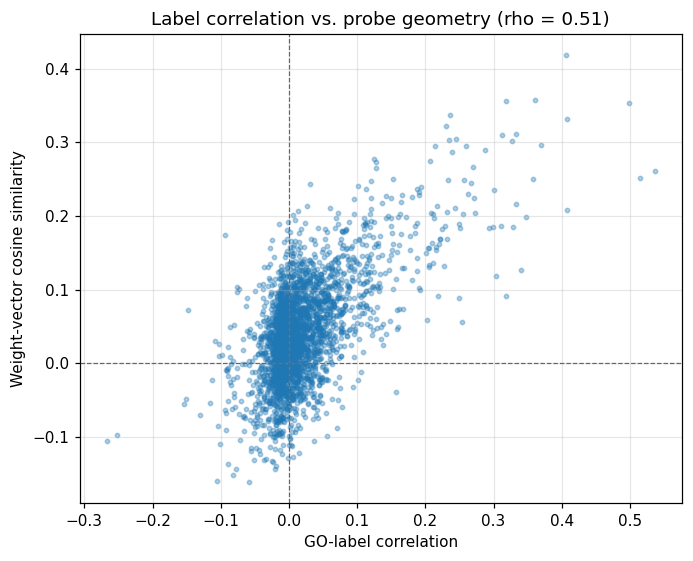

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
scatter = ax.scatter(corr_pairs, cos_pairs, s=8, alpha=0.35, color="#1f77b4")
ax.axhline(0, color="0.4", lw=0.8, ls="--")
ax.axvline(0, color="0.4", lw=0.8, ls="--")
ax.set_xlabel("GO-label correlation")
ax.set_ylabel("Weight-vector cosine similarity")
ax.set_title(f"Label correlation vs. probe geometry (rho = {rho:.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_weight_vs_label_correlation.png")
plt.show()

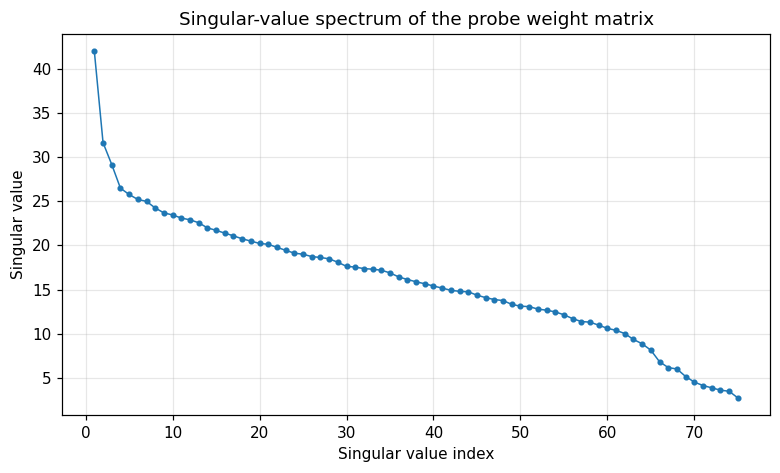

In [19]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(np.arange(1, len(s) + 1), s, "o-", ms=3, lw=1)
ax.set_xlabel("Singular value index")
ax.set_ylabel("Singular value")
ax.set_title("Singular-value spectrum of the probe weight matrix")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_singular_values.png")
plt.show()

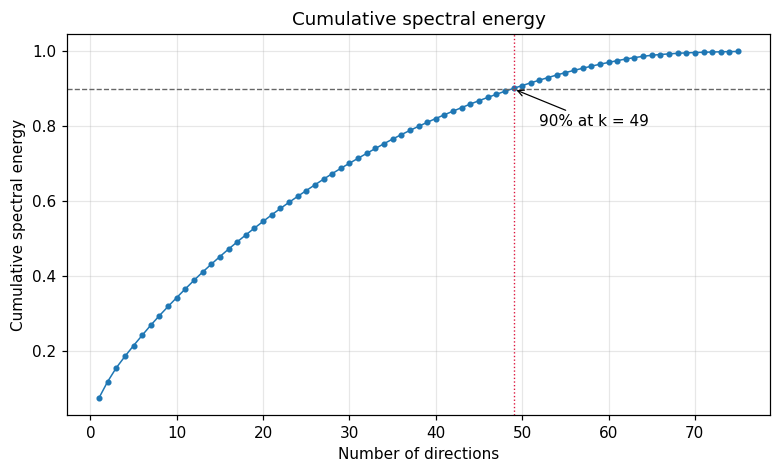

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(np.arange(1, len(s) + 1), cumulative, "o-", ms=3, lw=1)
ax.axhline(0.90, color="0.4", lw=0.9, ls="--")
ax.axvline(rank90, color="crimson", lw=0.9, ls=":")
ax.annotate(f"90% at k = {rank90}", xy=(rank90, 0.90), xytext=(rank90 + 3, 0.80),
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("Number of directions")
ax.set_ylabel("Cumulative spectral energy")
ax.set_title("Cumulative spectral energy")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_cumulative_energy.png")
plt.show()

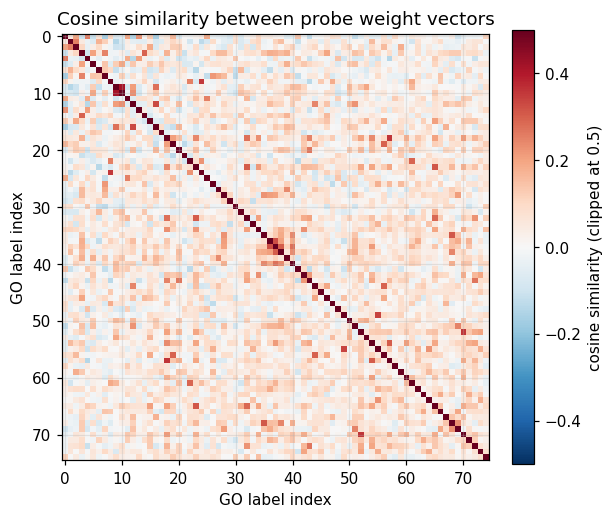

In [21]:
fig, ax = plt.subplots(figsize=(5.6, 5.0))
limit = 0.5   # the off-diagonal range is about [-0.16, 0.42]
image = ax.imshow(cosine, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xlabel("GO label index")
ax.set_ylabel("GO label index")
ax.set_title("Cosine similarity between probe weight vectors")
fig.colorbar(image, ax=ax, fraction=0.046, label="cosine similarity (clipped at 0.5)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_cosine_matrix.png")
plt.show()

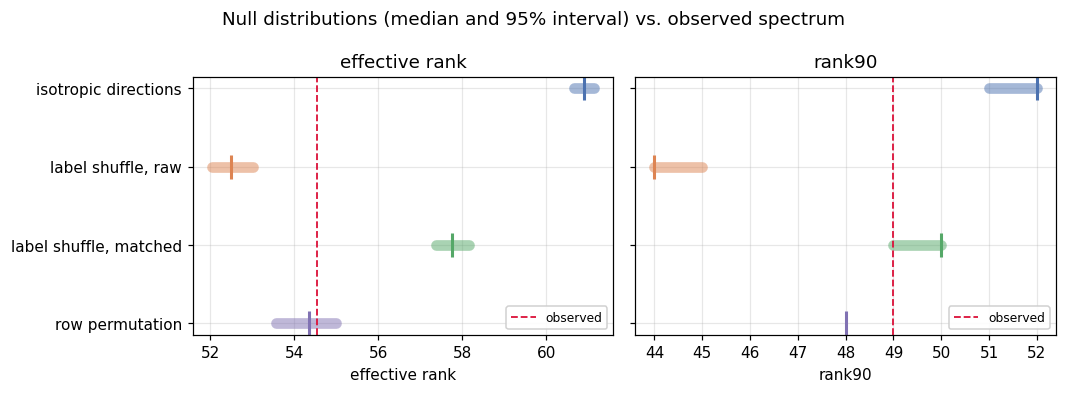

In [22]:
null_series = [
    ("isotropic directions", iso_er, iso_r90, "#4c72b0"),
    ("label shuffle, raw", shuffle_raw_er, shuffle_raw_r90, "#dd8452"),
    ("label shuffle, matched", shuffle_matched_er, shuffle_matched_r90, "#55a868"),
    ("row permutation", row_er, row_r90, "#8172b3"),
]

fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.6), sharey=True)
for ax, index, observed, title in [
    (axes[0], 0, observed_er, "effective rank"),
    (axes[1], 1, observed_r90, "rank90"),
]:
    for row, (name, er_values, r90_values, color) in enumerate(null_series):
        values = np.asarray([er_values, r90_values][index])
        lo, mid, hi = np.percentile(values, [2.5, 50, 97.5])
        ax.plot([lo, hi], [row, row], color=color, lw=7, alpha=0.5,
                solid_capstyle="round")
        ax.plot([mid], [row], "|", color=color, ms=16, mew=2)
    ax.axvline(observed, color="crimson", ls="--", lw=1.2, label="observed")
    ax.set_title(title)
    ax.set_xlabel(title)
    ax.legend(loc="lower right", fontsize=8, framealpha=0.9)

axes[0].set_yticks(range(len(null_series)))
axes[0].set_yticklabels([series[0] for series in null_series])
axes[0].invert_yaxis()
fig.suptitle("Null distributions (median and 95% interval) vs. observed spectrum")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_null_ladder.png")
plt.show()

## 8. Results export

All numbers used in the report are written to `results.json`. Re-running this
notebook regenerates the file, so the manuscript can always be checked against it.

In [23]:
results = {
    "data": {
        "n_proteins": int(len(raw)),
        "n_features": int(X.shape[1]),
        "n_labels": int(len(labels)),
        "n_positives": int(Y.sum()),
        "mean_labels_per_protein": float(Y.sum(axis=1).mean()),
        "n_proteins_with_label": int((Y.sum(axis=1) > 0).sum()),
        "n_terms_in_export": int(len(label_counts)),
        "n_train": int(X_train.shape[0]),
        "n_test": int(X_test.shape[0]),
    },
    "probe": {
        "mean_roc_auc": float(per_label.roc_auc.mean()),
        "mean_average_precision": float(per_label.average_precision.mean()),
        "n_labels_scored": int(len(per_label)),
    },
    "geometry": {
        "rank_W": int(rank_W),
        "rank_tolerance": float(rank_tol),
        "sigma_1": float(s[0]),
        "max_abs_cosine": float(abs(c_star)),
        "max_cosine_pair": [labels[i_closest], labels[j_closest]],
        "closest_pair_angle_deg": float(np.degrees(np.arccos(abs(c_star)))),
        "closest_pair_sigma_ratio": float(sigma_ratio),
        "mean_abs_cosine": float(np.abs(pair_cos).mean()),
        "min_cosine": float(pair_cos.min()),
        "max_cosine": float(pair_cos.max()),
        "effective_rank": float(effective_rank),
        "rank90": int(rank90),
        "rank95": int(rank95),
        "cumulative_energy": {
            str(k): float(cumulative[k - 1]) for k in [1, 5, 10, 20, 30, 40, 50, 60, 75]
        },
        "subset_ranks": json.loads(subset_table.to_json(orient="records")),
    },
    "nulls": {
        "observed_effective_rank": float(observed_er),
        "observed_rank90": int(observed_r90),
        "isotropic": {
            "er_mean": float(iso_er.mean()),
            "er_ci": [float(np.percentile(iso_er, q)) for q in (2.5, 97.5)],
            "r90_mean": float(iso_r90.mean()),
            "r90_ci": [float(np.percentile(iso_r90, q)) for q in (2.5, 97.5)],
            "p_er": empirical_p(iso_er, observed_er),
            "p_r90": empirical_p(iso_r90, observed_r90),
            "n": len(iso_er),
        },
        "label_shuffle_raw": {
            "er_mean": float(shuffle_raw_er.mean()),
            "er_ci": [float(np.percentile(shuffle_raw_er, q)) for q in (2.5, 97.5)],
            "r90_mean": float(shuffle_raw_r90.mean()),
            "r90_ci": [float(np.percentile(shuffle_raw_r90, q)) for q in (2.5, 97.5)],
            "p_er": empirical_p(shuffle_raw_er, observed_er),
            "p_r90": empirical_p(shuffle_raw_r90, observed_r90),
            "n": len(shuffle_raw_er),
        },
        "label_shuffle_matched": {
            "er_mean": float(shuffle_matched_er.mean()),
            "er_ci": [float(np.percentile(shuffle_matched_er, q)) for q in (2.5, 97.5)],
            "r90_mean": float(shuffle_matched_r90.mean()),
            "r90_ci": [float(np.percentile(shuffle_matched_r90, q)) for q in (2.5, 97.5)],
            "p_er": empirical_p(shuffle_matched_er, observed_er),
            "p_r90": empirical_p(shuffle_matched_r90, observed_r90),
            "n": len(shuffle_matched_er),
        },
        "row_permutation": {
            "er_mean": float(row_er.mean()),
            "er_ci": [float(np.percentile(row_er, q)) for q in (2.5, 97.5)],
            "r90_mean": float(row_r90.mean()),
            "r90_ci": [float(np.percentile(row_r90, q)) for q in (2.5, 97.5)],
            "p_er": empirical_p(row_er, observed_er),
            "p_r90": empirical_p(row_r90, observed_r90),
            "n": len(row_er),
        },
    },
    "labels": {
        "spearman_rho": float(rho),
        "spearman_p": float(p_value),
        "partial_rho": float(rho_partial),
        "partial_p": float(p_partial),
        "n_pairs": int(len(cos_pairs)),
    },
}

Path("results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results["nulls"], indent=2))

{
  "observed_effective_rank": 54.53968048095703,
  "observed_rank90": 49,
  "isotropic": {
    "er_mean": 60.90574677999335,
    "er_ci": [
      60.66484413759973,
      61.14165000833238
    ],
    "r90_mean": 51.959,
    "r90_ci": [
      51.0,
      52.0
    ],
    "p_er": 0.000999000999000999,
    "p_r90": 0.000999000999000999,
    "n": 1000
  },
  "label_shuffle_raw": {
    "er_mean": 52.508189067840576,
    "er_ci": [
      52.037206935882566,
      53.02620429992676
    ],
    "r90_mean": 44.24,
    "r90_ci": [
      44.0,
      45.0
    ],
    "p_er": 1.0,
    "p_r90": 1.0,
    "n": 200
  },
  "label_shuffle_matched": {
    "er_mean": 57.74621921539307,
    "er_ci": [
      57.35987319946289,
      58.158927822113036
    ],
    "r90_mean": 49.645,
    "r90_ci": [
      49.0,
      50.0
    ],
    "p_er": 0.004975124378109453,
    "p_r90": 0.3582089552238806,
    "n": 200
  },
  "row_permutation": {
    "er_mean": 54.321741638183596,
    "er_ci": [
      53.56741237640381,
   

### Summary

| Result | Value |
| --- | --- |
| Rank of `W` | 75 / 75, tolerance about 4.5e-12 |
| Closest pair | `GO:0005789` / `GO:0005783`, absolute cosine 0.4177 |
| Spectral concentration | effective rank 54.54, rank90 49 |
| Isotropic null | effective rank 60.91, p < 0.001 |
| Label shuffle, matched | effective rank 57.75, p = 0.005 |
| Row permutation | effective rank 54.32, p = 0.73 |
| Label correlation vs. cosine | Spearman 0.5074, partial 0.4889 |

The probe's weight vectors are linearly independent and the spectrum is moderately
concentrated. The concentration is reproduced exactly by a null that preserves the
co-occurrence structure of the labels, so the geometry is best read as a reflection
of label statistics rather than as evidence of feature superposition in the
embedding space.

Note that this dataset has 75 labels in 480 dimensions, so there is no capacity
pressure that would make superposition necessary in the first place.